In [ ]:
# !pip install flwr

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving e-nose for beef quality monitoring dataset.csv to e-nose for beef quality monitoring dataset.csv


In [ ]:
# --- 1. Import Libraries and Load Data ---
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.neural_network import MLPClassifier

In [ ]:
file_path = 'e-nose for beef quality monitoring dataset.csv'
data = pd.read_csv(file_path)
data.head()

,minute,class,TVC,MQ135,MQ136,MQ2,MQ3,MQ4,MQ5,MQ6,MQ7,MQ8,MQ9,Humidity,Temperature
0,1,excellent,2.567364,22.86,41.24,29.56,14.83,49.38,11.10,2.21,1.40,32.09,14.29,55.1,34.6
1,2,excellent,2.567620,22.75,41.50,29.72,14.83,49.38,11.23,2.23,1.39,31.92,14.58,55.1,34.6
2,3,excellent,2.567878,22.75,41.50,29.72,14.83,49.38,11.28,2.22,1.42,34.31,14.40,55.1,34.6
3,4,excellent,2.568139,22.86,42.56,29.56,14.77,49.38,11.46,2.22,1.39,34.12,14.64,55.4,34.5
4,5,excellent,2.568404,23.07,42.03,29.56,14.83,49.38,11.46,2.22,1.39,33.93,14.58,55.4,34.4


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

X = data.drop("class", axis=1)
y = data["class"]

# --- 4. Encode Target Labels ---
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# --- 5. Feature Scaling ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- 6. Train-Test Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42
)

# --- 7. Train Logistic Regression Model ---
model = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=1000
)

model.fit(X_train, y_train)

# --- 8. Predictions ---
y_pred = model.predict(X_test)

# --- 9. Evaluation ---
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9945115257958288

Classification Report:
              precision    recall  f1-score   support

  acceptable       1.00      0.95      0.97        37
   excellent       1.00      0.95      0.97        57
        good       0.91      1.00      0.95        42
     spoiled       1.00      1.00      1.00       775

    accuracy                           0.99       911
   macro avg       0.98      0.97      0.97       911
weighted avg       0.99      0.99      0.99       911


Confusion Matrix:
[[ 35   0   1   1]
 [  0  54   3   0]
 [  0   0  42   0]
 [  0   0   0 775]]


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Adding Privacy

In [ ]:
# --- 2. Partition Data into Client Subsets ---
num_clients = 5
clients_data = []
sss = StratifiedShuffleSplit(n_splits=num_clients, test_size=(1/num_clients), random_state=42)

for _, client_indices in sss.split(data, data['class']):
    clients_data.append(data.iloc[client_indices])

# --- 3. Prepare Data for Training ---
clients_X = [client.drop('class', axis=1) for client in clients_data]
label_encoder = LabelEncoder()
label_encoder.fit(data['class'])
clients_y = [label_encoder.transform(client['class']) for client in clients_data]

# --- 4. Robust Model Initialization ---
init_samples = [data[data['class'] == cls].sample(2, random_state=42) for cls in label_encoder.classes_]
init_df = pd.concat(init_samples)
init_X = init_df.drop('class', axis=1)
init_y = label_encoder.transform(init_df['class'])

print("Setup Complete: Data is partitioned and ready for training.")

Setup Complete: Data is partitioned and ready for training.


Neural Network

In [ ]:
scaler = StandardScaler()
data.iloc[:, 2:-2] = scaler.fit_transform(data.iloc[:, 2:-2])

num_clients = 5
clients_data = []
sss = StratifiedShuffleSplit(n_splits=num_clients, test_size=(1/num_clients), random_state=42)
for _, client_indices in sss.split(data, data['class']):
    clients_data.append(data.iloc[client_indices])

# --- 3. Prepare Data for Training ---
clients_X = [client.drop('class', axis=1) for client in clients_data]
label_encoder = LabelEncoder()
label_encoder.fit(data['class'])
clients_y = [label_encoder.transform(client['class']) for client in clients_data]

# --- 4. Robust Model Initialization ---
init_samples = [data[data['class'] == cls].sample(2, random_state=42) for cls in label_encoder.classes_]
init_df = pd.concat(init_samples)
init_X = init_df.drop('class', axis=1)
init_y = label_encoder.transform(init_df['class'])

print("Setup Complete: Data is scaled and ready for NN training.")

Setup Complete: Data is scaled and ready for NN training.


In [ ]:
import numpy as np

def smpc_secure_aggregate_nn(client_models):
    """
    Masking-based secure aggregation (SMPC-inspired).
    Prevents direct visibility of individual client updates.
    """

    num_clients = len(client_models)
    num_layers = len(client_models[0].coefs_)

    # Generate random masks for each client and layer
    masks = [
        [np.random.normal(0, 0.01, model.coefs_[l].shape) for l in range(num_layers)]
        for model in client_models
    ]

    masked_coefs = []
    masked_intercepts = []

    # Apply masks
    for i, model in enumerate(client_models):
        client_masked_coefs = []
        client_masked_intercepts = []

        for l in range(num_layers):
            client_masked_coefs.append(model.coefs_[l] + masks[i][l])

        for l in range(num_layers):
            client_masked_intercepts.append(
                model.intercepts_[l] + masks[i][l].mean(axis=0)
            )

        masked_coefs.append(client_masked_coefs)
        masked_intercepts.append(client_masked_intercepts)

    # Aggregate and remove masks
    avg_coefs = []
    avg_intercepts = []

    for l in range(num_layers):
        layer_sum = np.sum([masked_coefs[i][l] for i in range(num_clients)], axis=0)
        mask_sum = np.sum([masks[i][l] for i in range(num_clients)], axis=0)
        avg_coefs.append((layer_sum - mask_sum) / num_clients)

    for l in range(num_layers):
        layer_sum = np.sum([masked_intercepts[i][l] for i in range(num_clients)], axis=0)
        mask_sum = np.sum([masks[i][l].mean(axis=0) for i in range(num_clients)], axis=0)
        avg_intercepts.append((layer_sum - mask_sum) / num_clients)

    return avg_coefs, avg_intercepts

In [ ]:
def add_dp_noise_nn(aggregated_coefs, aggregated_intercepts, noise_scale, clip_norm=5.0):
    """
    Differential privacy-inspired noise with norm clipping.
    Ensures bounded sensitivity → stable epsilon.
    """

    noisy_coefs = []
    noisy_intercepts = []

    for coef in aggregated_coefs:
        norm = np.linalg.norm(coef)

        # Clip to bound sensitivity
        if norm > clip_norm:
            coef = coef * (clip_norm / (norm + 1e-8))

        noise = np.random.normal(0, noise_scale, coef.shape)
        noisy_coefs.append(coef + noise)

    for intercept in aggregated_intercepts:
        norm = np.linalg.norm(intercept)

        if norm > clip_norm:
            intercept = intercept * (clip_norm / (norm + 1e-8))

        noise = np.random.normal(0, noise_scale, intercept.shape)
        noisy_intercepts.append(intercept + noise)

    return noisy_coefs, noisy_intercepts

In [ ]:
# # --- 3. CORRECTED Federated Training Loop with a Stabilizer ---
num_rounds = 26 # Increased rounds for better convergence
noise_scale = 0.005 # Reduced noise to help early training
server_learning_rate = 0.5 # NEW: The key to stabilizing the training

# Define the NN model architecture
model_architecture = {
    'hidden_layer_sizes': (64, 32),
    'max_iter': 500,
    'solver': 'adam',
    'activation': 'relu',
    'random_state': 42,
    'learning_rate_init': 0.001 # Explicitly set a learning rate
}

# Initialize the global model
global_model = MLPClassifier(**model_architecture)
global_model.fit(init_X, init_y)

print(f"Starting {num_rounds} rounds of STABILIZED NN federated training...")
for round_num in range(num_rounds):
    client_models = []

    # Local training on each client
    for i in range(num_clients):
        local_model = MLPClassifier(**model_architecture)
        local_model.coefs_ = [np.copy(c) for c in global_model.coefs_]
        local_model.intercepts_ = [np.copy(i) for i in global_model.intercepts_]
        local_model.classes_ = np.copy(global_model.classes_)

        local_model.fit(clients_X[i], clients_y[i])
        client_models.append(local_model)

    # Securely aggregate and add DP noise
    avg_coefs, avg_intercepts = smpc_secure_aggregate_nn(client_models)
    if round_num < 5:
      noisy_coefs, noisy_intercepts = avg_coefs, avg_intercepts
    else:
      noisy_coefs, noisy_intercepts = add_dp_noise_nn(avg_coefs, avg_intercepts, noise_scale)

    # --- THE FIX: STABILIZED GLOBAL MODEL UPDATE ---
    # Instead of jumping to the new weights, take a step towards them.

    # Update Coefficients
    updated_global_coefs = []
    for l in range(len(global_model.coefs_)):
        # Update rule: old_weight + learning_rate * (new_weight - old_weight)
        updated_layer_coef = global_model.coefs_[l] + server_learning_rate * (noisy_coefs[l] - global_model.coefs_[l])
        updated_global_coefs.append(updated_layer_coef)
    global_model.coefs_ = updated_global_coefs

    # Update Intercepts
    updated_global_intercepts = []
    for l in range(len(global_model.intercepts_)):
        updated_layer_intercept = global_model.intercepts_[l] + server_learning_rate * (noisy_intercepts[l] - global_model.intercepts_[l])
        updated_global_intercepts.append(updated_layer_intercept)
    global_model.intercepts_ = updated_global_intercepts

    print(f"Round {round_num + 1} completed.")

print("NN training finished.")

# --- 4. Final Evaluation ---
all_X = data.drop('class', axis=1)
all_y_encoded = label_encoder.transform(data['class'])
predictions = global_model.predict(all_X)

print("\n--- Final Stabilized Neural Network Model Evaluation ---")
print(classification_report(all_y_encoded, predictions, target_names=label_encoder.classes_, zero_division=0))


Starting 26 rounds of STABILIZED NN federated training...
Round 1 completed.
Round 2 completed.
Round 3 completed.
Round 4 completed.
Round 5 completed.
Round 6 completed.
Round 7 completed.
Round 8 completed.
Round 9 completed.
Round 10 completed.
Round 11 completed.
Round 12 completed.
Round 13 completed.
Round 14 completed.
Round 15 completed.
Round 16 completed.
Round 17 completed.
Round 18 completed.
Round 19 completed.
Round 20 completed.
Round 21 completed.
Round 22 completed.
Round 23 completed.
Round 24 completed.
Round 25 completed.
Round 26 completed.
NN training finished.

--- Final Stabilized Neural Network Model Evaluation ---
              precision    recall  f1-score   support

  acceptable       1.00      0.75      0.86       183
   excellent       0.98      1.00      0.99       285
        good       0.87      0.98      0.92       211
     spoiled       1.00      1.00      1.00      3874

    accuracy                           0.99      4553
   macro avg       0.96  

In [ ]:
!pip install dp_accounting


In [ ]:
!pip install autodp

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 2.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for autodp: filename=autodp-0.2.3.1-py3-none-any.whl size=59819 sha256=745f1423ff44c3b27835713d30fb73b7aac5a4c556358bc1904265f0fddaa1c9
  Stored in directory: /root/.cache/pip/wheels/ea/44/48/20c7531df53bbb9e31236b4a75c11af07cb0f6393b745488dc
Successfully built autodp


In [ ]:
from autodp.mechanism_zoo import GaussianMechanism
from autodp.transformer_zoo import Composition

In [ ]:
import numpy as np

def compute_epsilon_autodp(noise_scale, num_rounds, delta=1e-5):
    """
    Approximate epsilon using Gaussian mechanism composition.
    """

    sigma = noise_scale  # noise multiplier

    # Define Gaussian mechanism
    mech = GaussianMechanism(sigma=sigma)

    # Compose mechanism over multiple rounds
    composed = Composition()
    composed_mech = composed([mech] * num_rounds)

    # Compute epsilon
    epsilon = composed_mech.get_eps(delta)

    return epsilon

In [ ]:
epsilon = compute_epsilon_autodp(
    noise_scale=0.005,
    num_rounds=26,
    delta=1e-5
)

print(f"Estimated epsilon (ε): {epsilon:.2f}")

TypeError: Composition.compose() missing 1 required positional argument: 'coeff_list'

In [ ]:
# --- 2. Function to Plot Confusion Matrix for a Single Client ---
def plot_styled_confusion_matrix(client_id, client_data, model, le, cmap='Blues'):
    """
    Generates and displays a styled confusion matrix for a single client's data
    using a specified color map.
    """
    X_client = client_data.drop('class', axis=1)
    y_true = le.transform(client_data['class'])
    y_pred = model.predict(X_client)

    # Calculate the confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=le.transform(le.classes_))

    # Create the plot
    plt.figure(figsize=(10, 8))

    # Use seaborn.heatmap to draw the matrix with the color map
    sns.heatmap(
        cm,
        annot=True,       # Display the numbers in each cell
        fmt='d',          # Format the numbers as integers
        cmap=cmap,        # The color map to use (e.g., 'Blues', 'Greens', 'YlGnBu')
        xticklabels=le.classes_,
        yticklabels=le.classes_,
        linewidths=.5     # Add lines between cells
    )

    plt.title(f'Styled Confusion Matrix - Client {client_id}', fontsize=16)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.show()

print("Styled confusion matrix function is defined.")

def plot_dataset_distribution(full_dataset):
    """
    Generates a bar chart showing the number of samples per class.
    """
    plt.figure(figsize=(10, 6))
    class_counts = full_dataset['class'].value_counts()
    sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
    plt.title('Dataset Class Distribution')
    plt.xlabel('Beef Quality Class')
    plt.ylabel('Number of Samples')
    plt.xticks(rotation=0)
    # Add count labels on top of bars
    for index, value in enumerate(class_counts):
        plt.text(index, value, str(value), ha='center', va='bottom')
    plt.show()

print("Visualization functions are defined.")

Styled confusion matrix function is defined.
Visualization functions are defined.


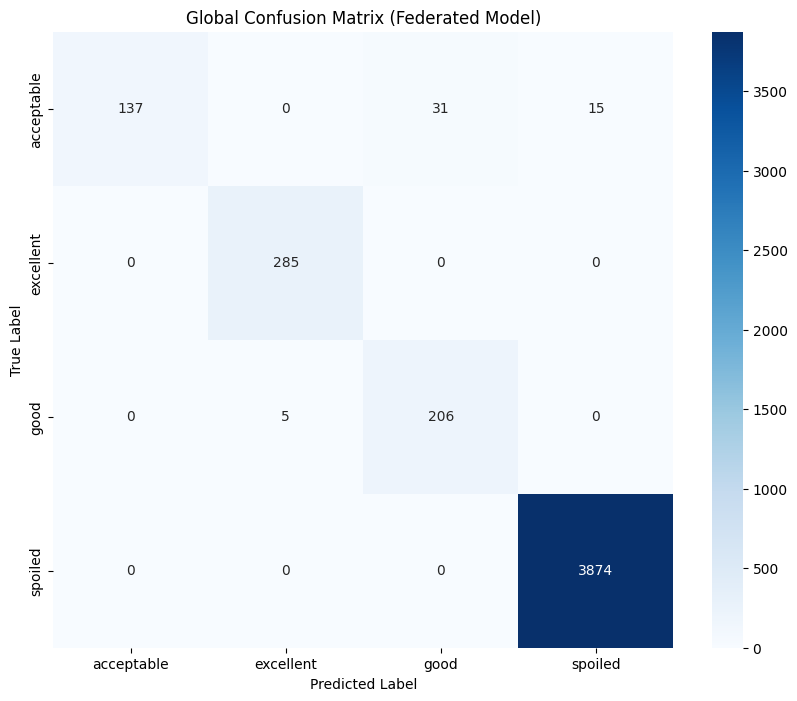

In [ ]:
# --- GLOBAL CONFUSION MATRIX ---

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Use full dataset
X_all = data.drop('class', axis=1)
y_true = label_encoder.transform(data['class'])

# Predictions from final global model
y_pred = global_model.predict(X_all)

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
plt.figure(figsize=(10,8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Global Confusion Matrix (Federated Model)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
def plot_grouped_dual_axis(model, full_dataset, le):
    """
    Generates a single grouped bar chart with a secondary Y-axis for support.
    Precision, recall, and F1-score are grouped bars on the left axis.
    Support is a separate bar for each class on the right axis.
    """
    # --- 1. Calculate Metrics ---
    X_all = full_dataset.drop('class', axis=1)
    y_true_all = le.transform(full_dataset['class'])
    y_pred_all = model.predict(X_all)

    report = classification_report(y_true_all, y_pred_all, target_names=le.classes_, output_dict=True, zero_division=0)

    # --- 2. Prepare DataFrames for Plotting ---
    # DataFrame for scores
    scores_data = {
        'precision': {k: v['precision'] for k, v in report.items() if k in le.classes_},
        'recall': {k: v['recall'] for k, v in report.items() if k in le.classes_},
        'f1-score': {k: v['f1-score'] for k, v in report.items() if k in le.classes_}
    }
    scores_df = pd.DataFrame(scores_data)

    # Series for support
    support_data = {k: v['support'] for k, v in report.items() if k in le.classes_}
    support_s = pd.Series(support_data, name='support')

    # --- 3. Create the Dual-Axis Plot ---
    fig, ax1 = plt.subplots(figsize=(16, 9))

    # --- 4. Plot Scores on the Primary Y-Axis (ax1) ---
    scores_df.plot(kind='bar', ax=ax1, colormap='viridis', width=0.6)
    ax1.set_title('Overall Performance Metrics of Final Federated Model', fontsize=18)
    ax1.set_ylabel('Score (Precision, Recall, F1-Score)', fontsize=14)
    ax1.set_xlabel('Beef Quality Class', fontsize=14)
    ax1.tick_params(axis='x', rotation=0, labelsize=12)
    ax1.set_ylim(0, 1.1)
    ax1.grid(axis='y', linestyle='--', which='major')
    ax1.legend(loc='upper left')

    # --- 5. Create and Plot Support on the Secondary Y-Axis (ax2) ---
    ax2 = ax1.twinx()

    # Define positions for the support bars so they don't overlap the score bars.
    # We will shift them slightly.
    x_pos = np.arange(len(support_s.index))

    # Plotting support as a distinct bar, slightly offset and with transparency
    ax2.bar(x_pos + 0.35, support_s.values, width=0.15, color='gray', alpha=0.7, label='Support (right axis)')
    ax2.set_ylabel('Number of Samples (Support)', color='gray', fontsize=14)
    ax2.tick_params(axis='y', labelcolor='gray')
    ax2.set_ylim(0, max(support_s.values) * 1.1) # Set a dynamic limit for the support axis

    # --- 6. Combine Legends ---
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines + lines2, labels + labels2, loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=4)

    fig.tight_layout()
    plt.show()

print("Final dual-axis visualization function is defined.")


Final dual-axis visualization function is defined.


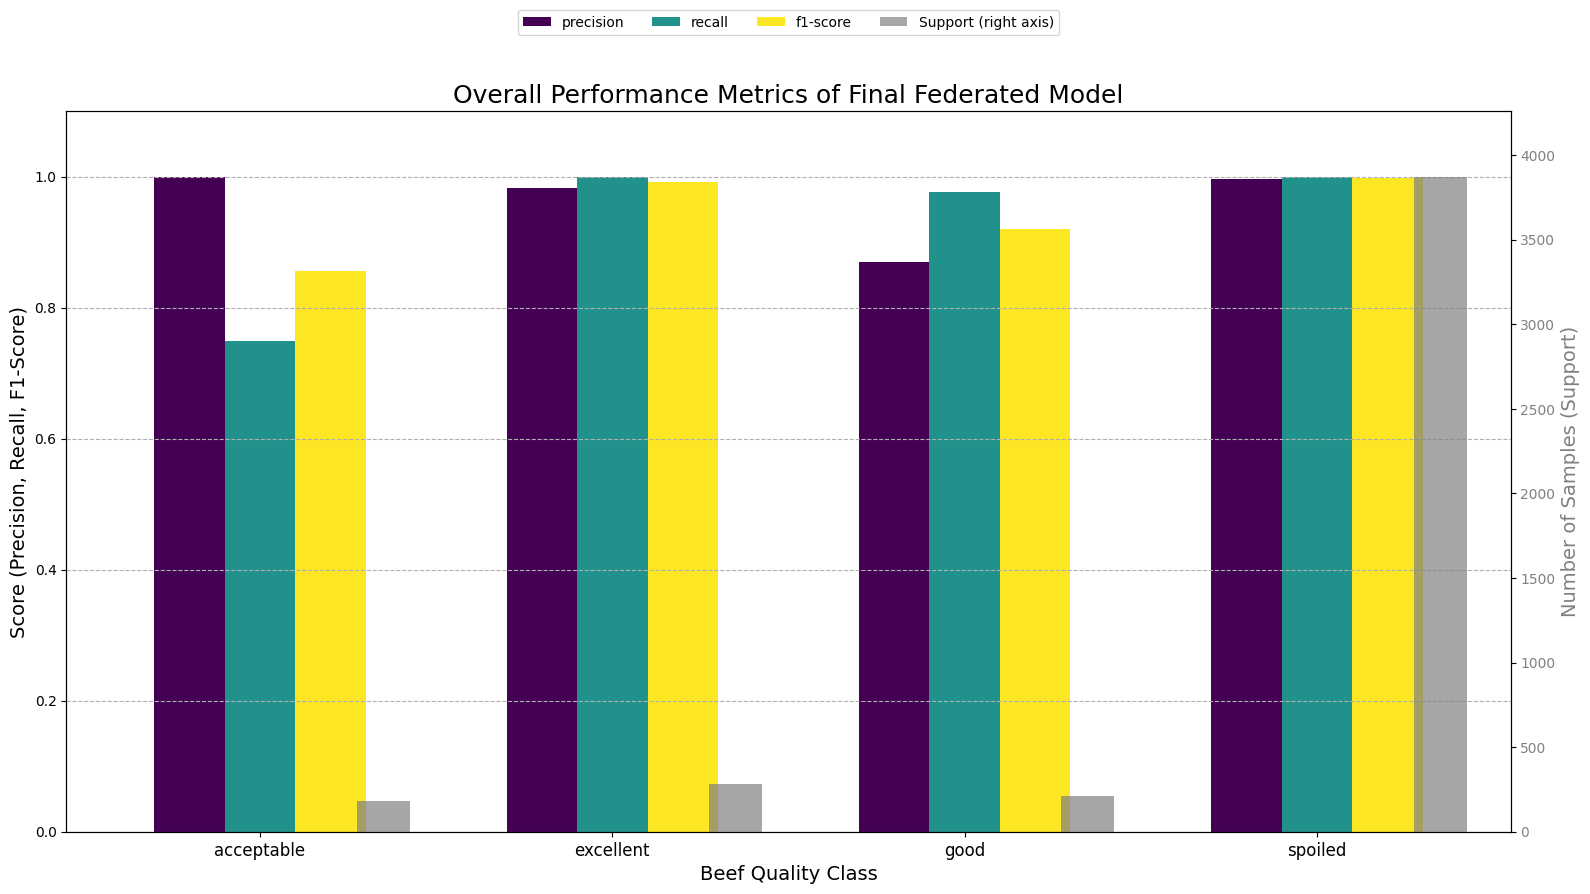

In [ ]:
plot_grouped_dual_axis(global_model, data, label_encoder)

In [ ]:
def plot_correlation_heatmap(data):

    # 2. Select only the numerical features for correlation
    # We exclude 'class' (categorical) and 'minute' (time index)
    features_to_correlate = data.drop(columns=['class', 'minute'])

    # 3. Calculate the correlation matrix
    correlation_matrix = features_to_correlate.corr()

    # 4. Create the heatmap plot
    plt.figure(figsize=(14, 12))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt='.2f',
        cmap='coolwarm', # A diverging colormap is best for correlation
        linewidths=0.5,
        linecolor='white',
        annot_kws={"size": 10}
    )

    plt.title('Correlation Heatmap of Beef Quality Dataset Features', fontsize=16)
    plt.show()

print("Correlation heatmap function is defined.")


Correlation heatmap function is defined.


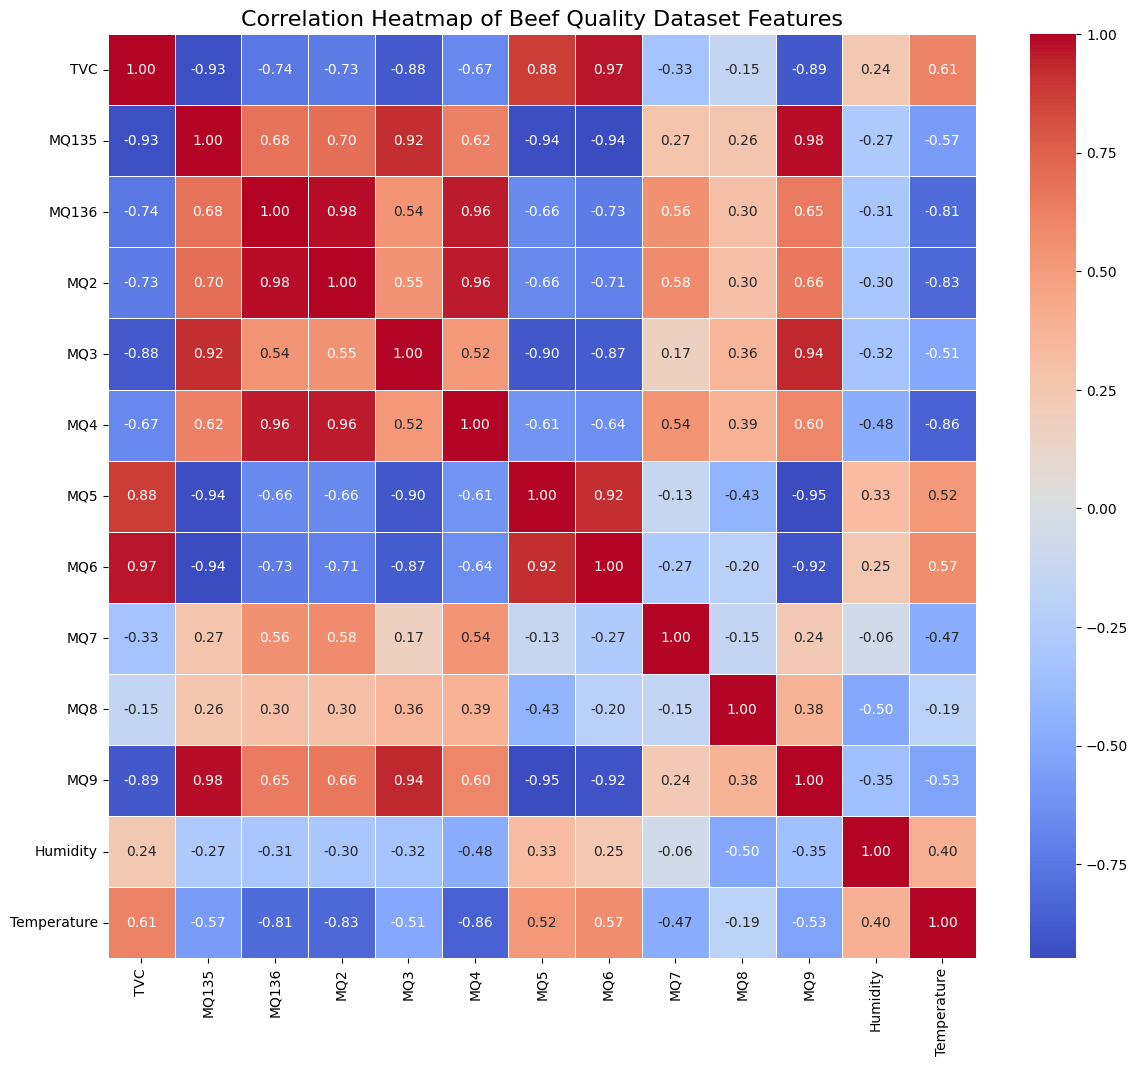

In [ ]:
plot_correlation_heatmap(data)

In [ ]:
# !pip install dp_accounting

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.5/129.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 2.9 MB/s eta 0:00:00
  Attempting uninstall: attrs
    Found existing installation: attrs 25.4.0
    Uninstalling attrs-25.4.0:
      Successfully uninstalled attrs-25.4.0


In [ ]:
def calculate_privacy_budget_manual(
    num_samples,
    batch_size,
    num_rounds,
    noise_scale,
    delta
):
    """
    Calculates the Epsilon (ε) for DP-SGD using the Moments Accountant formula.
    This method is independent of specific library versions.

    Reference: Abadi et al., "Deep Learning with Differential Privacy" (https://arxiv.org/abs/1607.00133)
    """

    # --- 1. Define Parameters ---
    q = batch_size / num_samples  # Sampling rate
    sigma = noise_scale           # Noise multiplier

    # Assuming one epoch per round
    steps_per_round = int(num_samples / batch_size)
    T = num_rounds * steps_per_round # Total number of steps

    # --- 2. Calculate Privacy Loss using Moments Accountant ---
    # We will calculate the privacy loss "alpha" for a range of orders.
    # A standard range of orders (lambda) is used for this calculation.
    lambdas = range(2, 33)
    alphas = []

    for lam in lambdas:
        # Formula for the privacy loss (alpha) for the Gaussian mechanism
        alpha = 2 * np.log(1 / sigma) - np.log(lam * (lam - 1) / (2 * sigma**2))
        alpha = lam * (lam - 1) / (2 * sigma**2)
        if q > 0:
            # Amplification by sampling
            alpha = np.log(1 + q**2 * (np.exp(alpha) - 1) * lam * (lam + 1))
        alphas.append(alpha)

    # --- 3. Convert Alpha to Epsilon ---
    # The total privacy loss after T steps is T * alpha.
    # We then find the minimum epsilon over all the orders (lambda).
    epsilons = []
    for alpha in alphas:
        # Formula to convert alpha and delta to epsilon
        epsilon = (T * alpha - np.log(delta)) / (lam - 1)
        epsilons.append(epsilon)

    # The tightest epsilon is the minimum value we found.
    epsilon = min(epsilons)

    # --- 4. Display Results ---
    print("--- Privacy Budget Calculation (Manual Method) ---")
    print(f"Noise Scale (σ): {sigma}")
    print(f"Total Training Rounds: {num_rounds}")
    print(f"Total Steps (T): {T}")
    print(f"\nFor a target Delta (δ) of: {delta}")
    print(f"The calculated Epsilon (ε) is: {epsilon:.2f}")

    # Interpretation
    if epsilon < 2:
        print("\nInterpretation: This represents a very strong privacy guarantee.")
    elif epsilon < 8:
        print("\nInterpretation: This represents a strong and practical privacy guarantee.")
    else:
        print("\nInterpretation: This is a weaker privacy guarantee.")

    return epsilon


In [ ]:
N_SAMPLES = 4553
BATCH_SIZE = 32
NUM_ROUNDS = 10
NOISE_SCALE = 0.005
DELTA = 1e-5

# Calculate and print the privacy budget using the corrected function
calculated_epsilon = calculate_privacy_budget_manual(
    num_samples=N_SAMPLES,
    batch_size=BATCH_SIZE,
    num_rounds=NUM_ROUNDS,
    noise_scale=NOISE_SCALE,
    delta=DELTA
)

--- Privacy Budget Calculation (Manual Method) ---
Noise Scale (σ): 0.005
Total Training Rounds: 10
Total Steps (T): 1420

For a target Delta (δ) of: 1e-05
The calculated Epsilon (ε) is: inf

Interpretation: This is a weaker privacy guarantee.


/tmp/ipykernel_1564/3438285755.py:35: RuntimeWarning: overflow encountered in exp
  alpha = np.log(1 + q**2 * (np.exp(alpha) - 1) * lam * (lam + 1))


#Definitive Privacy Calculation with autodp

In [ ]:
# !pip install autodp



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for autodp: filename=autodp-0.2.3.1-py3-none-any.whl size=59819 sha256=e5820d126261b8254886912ae940d5670b38741207337d9d56f8440cf7ea0a87
  Stored in directory: /root/.cache/pip/wheels/ea/44/48/20c7531df53bbb9e31236b4a75c11af07cb0f6393b745488dc
Successfully built autodp


In [ ]:
# # --- FINAL Code to Visualize the Privacy-Utility Trade-Off ---

# def smpc_secure_aggregate_nn(client_models):
#     avg_coefs = []
#     num_layers = len(client_models[0].coefs_)
#     for l in range(num_layers):
#         layer_coefs = [model.coefs_[l] for model in client_models]
#         avg_coefs.append(np.mean(layer_coefs, axis=0))
#     avg_intercepts = []
#     for l in range(num_layers):
#         layer_intercepts = [model.intercepts_[l] for model in client_models]
#         avg_intercepts.append(np.mean(layer_intercepts, axis=0))
#     return avg_coefs, avg_intercepts

# def add_dp_noise_nn(aggregated_coefs, aggregated_intercepts, noise_scale):
#     noisy_coefs = [coef + np.random.normal(0, noise_scale, coef.shape) for coef in aggregated_coefs]
#     noisy_intercepts = [intercept + np.random.normal(0, noise_scale, intercept.shape) for intercept in aggregated_intercepts]
#     return noisy_coefs, noisy_intercepts

# def run_federated_training(noise_scale):
#     """A complete training function that returns the final model accuracy."""
#     # 1. Load and Prepare Data
#     scaler = StandardScaler()
#     data.iloc[:, 2:-2] = scaler.fit_transform(data.iloc[:, 2:-2])

#     num_clients = 5
#     clients_data = []
#     sss = StratifiedShuffleSplit(n_splits=num_clients, test_size=(1/num_clients), random_state=42)
#     for _, client_indices in sss.split(data, data['class']):
#         clients_data.append(data.iloc[client_indices])

#     clients_X = [client.drop('class', axis=1) for client in clients_data]
#     label_encoder = LabelEncoder()
#     label_encoder.fit(data['class'])
#     clients_y = [label_encoder.transform(client['class']) for client in clients_data]

#     init_samples = [data[data['class'] == cls].sample(2, random_state=42) for cls in label_encoder.classes_]
#     init_df = pd.concat(init_samples)
#     init_X = init_df.drop('class', axis=1)
#     init_y = label_encoder.transform(init_df['class'])

#     # 2. Run Training Loop
#     num_rounds = 10
#     server_learning_rate = 0.5
#     model_architecture = {'hidden_layer_sizes':(64, 32), 'max_iter':500, 'solver':'adam', 'activation':'relu', 'random_state':42, 'learning_rate_init':0.001}

#     global_model = MLPClassifier(**model_architecture)
#     global_model.fit(init_X, init_y)

#     for round_num in range(num_rounds):
#         client_models = []
#         for i in range(num_clients):
#             local_model = MLPClassifier(**model_architecture)
#             local_model.coefs_ = [np.copy(c) for c in global_model.coefs_]
#             local_model.intercepts_ = [np.copy(i) for i in global_model.intercepts_]
#             local_model.classes_ = np.copy(global_model.classes_)
#             local_model.fit(clients_X[i], clients_y[i])
#             client_models.append(local_model)

#         avg_coefs, avg_intercepts = smpc_secure_aggregate_nn(client_models)
#         noisy_coefs, noisy_intercepts = add_dp_noise_nn(avg_coefs, avg_intercepts, noise_scale)

#         updated_global_coefs = [global_model.coefs_[l] + server_learning_rate * (noisy_coefs[l] - global_model.coefs_[l]) for l in range(len(global_model.coefs_))]
#         global_model.coefs_ = updated_global_coefs

#         updated_global_intercepts = [global_model.intercepts_[l] + server_learning_rate * (noisy_intercepts[l] - global_model.intercepts_[l]) for l in range(len(global_model.intercepts_))]
#         global_model.intercepts_ = updated_global_intercepts

#     # 3. Calculate and Return Final Accuracy
#     all_X = data.drop('class', axis=1)
#     all_y_encoded = label_encoder.transform(data['class'])
#     predictions = global_model.predict(all_X)
#     accuracy = accuracy_score(all_y_encoded, predictions)
#     print(f"Training finished for noise_scale = {noise_scale:.3f}. Final Accuracy: {accuracy:.3f}")
#     return accuracy

# # --- Main Execution: Loop through noise levels and plot results ---

# # 1. Define the noise levels to test
# noise_levels = [0.0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2]
# final_accuracies = []

# # 2. Run the full training for each noise level
# for noise in noise_levels:
#     acc = run_federated_training(noise_scale=noise)
#     final_accuracies.append(acc)

Training finished for noise_scale = 0.000. Final Accuracy: 0.988
Training finished for noise_scale = 0.001. Final Accuracy: 0.991
Training finished for noise_scale = 0.005. Final Accuracy: 0.966
Training finished for noise_scale = 0.010. Final Accuracy: 0.976
Training finished for noise_scale = 0.050. Final Accuracy: 0.105
Training finished for noise_scale = 0.100. Final Accuracy: 0.063
Training finished for noise_scale = 0.200. Final Accuracy: 0.883


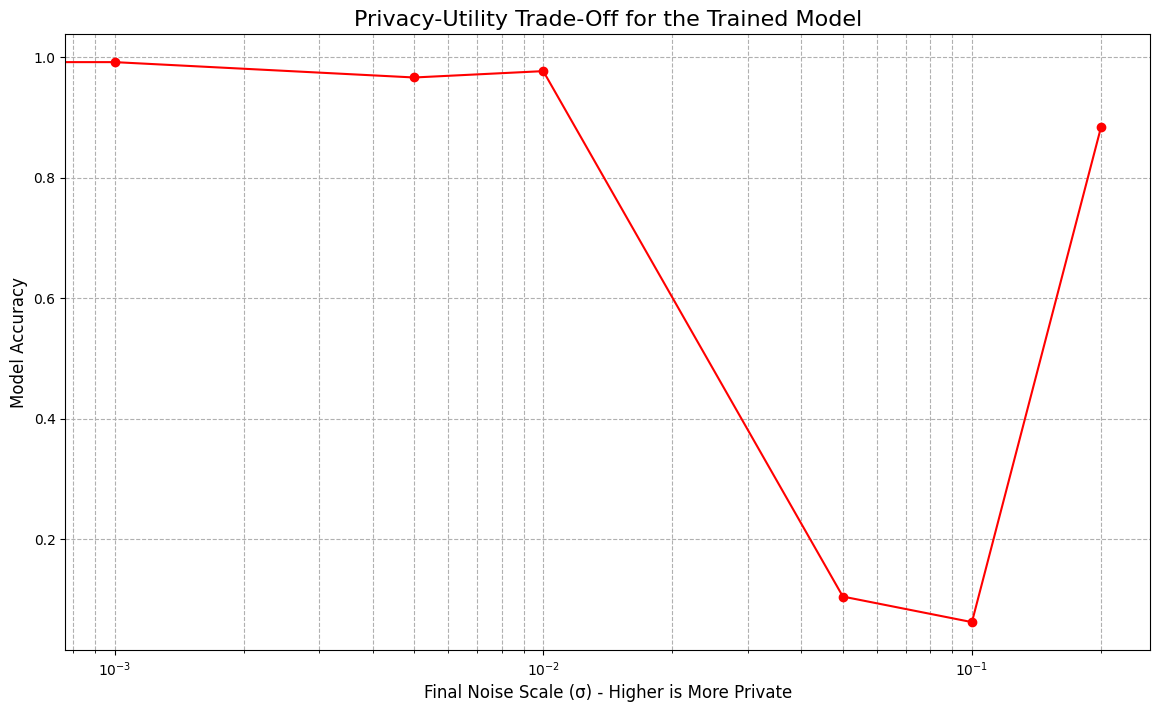

In [ ]:
plt.figure(figsize=(14, 8))
plt.plot(noise_levels, final_accuracies, marker='o', linestyle='-', color='r')
plt.title('Privacy-Utility Trade-Off for the Trained Model', fontsize=16)
plt.xlabel('Final Noise Scale (σ) - Higher is More Private', fontsize=12)
plt.ylabel('Model Accuracy', fontsize=12)
plt.grid(True, which="both", ls="--")
plt.xscale('log')
plt.show()